In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [2]:
df=pd.read_csv(r"Documents/data analytics/data/housing.csv")

#  HOUSING  PRICE  PREDICTION

## MACHINE LEARNING PROJECT

## INTRODUCTION

Housing prices are influenced by various factors such as location, house size, number of rooms, population, average income, and proximity to the ocean. Predicting house prices accurately is important for buyers, sellers, and real estate businesses.

This project focuses on predicting house prices using Machine Learning techniques. The California Housing Dataset is used for this analysis. Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn are used for data cleaning, data analysis, and visualization.

A Machine Learning algorithm called Random Forest Regression is used to build a prediction model. The model analyzes different housing features and predicts the median house value based on the available data.

The main objective of this project is to understand the factors affecting housing prices and develop a Machine Learning model that can predict house prices effectively.

## OBJECTIVES

The main objectives are:

1. To analyze the California Housing Dataset and understand its features.
2. To identify the important factors that influence house prices.
3. To perform data cleaning and handle missing values in the dataset.
4. To explore and visualize housing data using Python libraries.
5. To understand the relationship between different housing features and house prices.
6. To build a Machine Learning model using the Random Forest Regression algorithm.
7. To predict median house prices based on various housing features.
8. To evaluate the performance and accuracy of the Machine Learning model using suitable evaluation metrics.


## DATA UNDERSTANDING

In [3]:
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [4]:
df.shape

(20640, 10)

In [5]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [7]:
df.dtypes

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity        object
dtype: object

In [8]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [9]:
df.head(10)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
5,-122.25,37.85,52.0,919.0,213.0,413.0,193.0,4.0368,269700.0,NEAR BAY
6,-122.25,37.84,52.0,2535.0,489.0,1094.0,514.0,3.6591,299200.0,NEAR BAY
7,-122.25,37.84,52.0,3104.0,687.0,1157.0,647.0,3.1200,241400.0,NEAR BAY
8,-122.26,37.84,42.0,2555.0,665.0,1206.0,595.0,2.0804,226700.0,NEAR BAY
9,-122.25,37.84,52.0,3549.0,707.0,1551.0,714.0,3.6912,261100.0,NEAR BAY


In [10]:
df.tail()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND



- Data Understanding is the process of examining and analyzing the dataset to understand its structure, features, and characteristics.

- The California Housing Dataset contains 20,640 rows and 10 columns. It includes information about geographical location, housing age, total rooms, total bedrooms, population, households, median income, ocean proximity, and median house value.

- The dataset contains both numerical and categorical variables. The target variable for this project is median_house_value, which represents the median house value. Data understanding helps identify the important features and prepare the dataset for further analysis and machine learning.

## DATA CLEANING

In [11]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [12]:
df.duplicated().sum()

np.int64(0)

##### No duplicate records were found in the dataset

In [13]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [14]:
df["total_bedrooms"]= df["total_bedrooms"].fillna(df["total_bedrooms"].median())

In [15]:
df.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

##### Missing values were found in the total_bedrooms column. Instead of deleting the rows, the missing values were replaced with the median value to preserve the available data.

## EDA & DATA VISUALIZATION

### 1. STATISTICAL ANALYSIS 

In [16]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,536.838857,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,419.391878,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,297.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,643.250000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


##### The statistical analysis of the California Housing Dataset provides the following results:
- The dataset contains 20,640 records and 10 columns.
- The average housing median age is approximately 28.64 years.
- The average number of total rooms is 2,635.76.
- The average number of bedrooms is 536.84.
- The average population is 1,425.48.
- The average number of households is 499.54.
- The average median income is 3.87.
- The average median house value is approximately $206,855.82.
- The minimum house value is $14,999.
- The maximum house value is $500,001.

### 2. PRICE DISTRIBUTION

In [17]:
df["median_house_value"].describe()

count     20640.000000
mean     206855.816909
std      115395.615874
min       14999.000000
25%      119600.000000
50%      179700.000000
75%      264725.000000
max      500001.000000
Name: median_house_value, dtype: float64

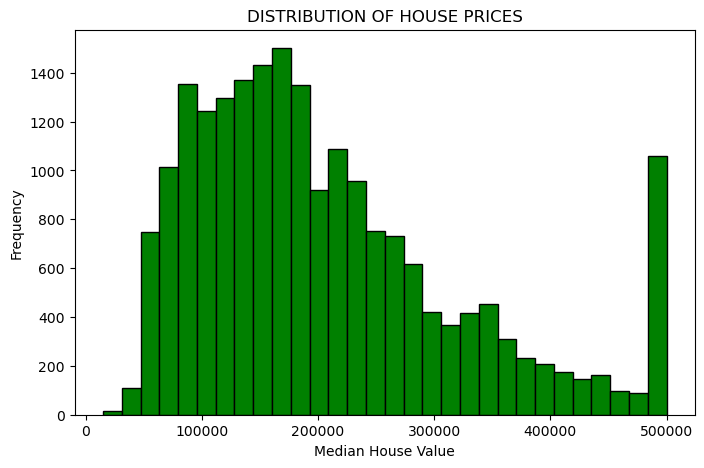

In [18]:
plt.figure(figsize=(8,5))

plt.hist(df['median_house_value'], bins=30,color="green",edgecolor='black')

plt.title('DISTRIBUTION OF HOUSE PRICES')
plt.xlabel('Median House Value')
plt.ylabel('Frequency')

plt.show()

1. Most houses are concentrated in the price range of approximately $100,000 to $200,000.

2. The highest frequency of houses is observed around the $150,000–$200,000 price range.

3. The number of houses generally decreases as house prices increase.

4. The distribution is positively skewed (Right-skewed), indicating that fewer houses have very high prices.

5. A noticeable peak appears at $500,001, which represents the maximum house value limit in the dataset.

   

### 3. INCOME VS HOUSE PRICE

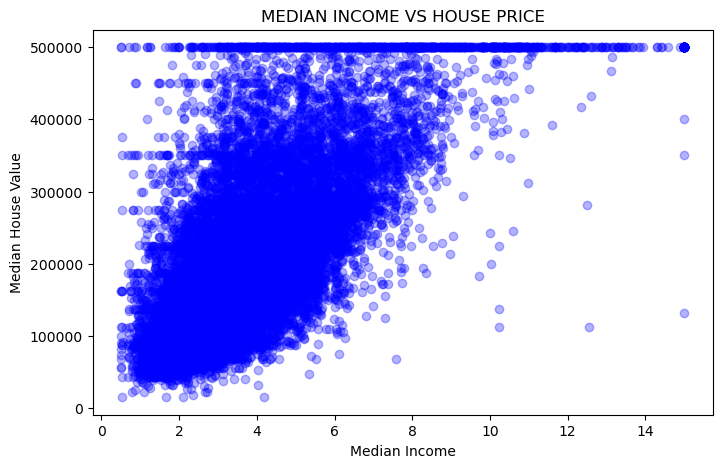

In [19]:
plt.figure(figsize=(8,5))

plt.scatter(df['median_income'],
            df['median_house_value'],
            alpha=0.3,
            color='BLUE')

plt.title('MEDIAN INCOME VS HOUSE PRICE')
plt.xlabel('Median Income')
plt.ylabel('Median House Value')

plt.show()

1. A positive relationship is observed between median income and median house value.

2. House prices generally increase as median income increases.

3. Most data points are concentrated within the median income range of 2 to 6.

4. Higher-income areas generally have higher house values.

5. Some variations in house prices are observed at similar income levels.

6. A horizontal pattern near $500,001 indicates the maximum house value limit in the dataset.

### 4. OCEN PROXIMITY VS HOUSE PRICE

In [20]:
avg_price = df.groupby("ocean_proximity")["median_house_value"].mean()

In [21]:
avg_price

ocean_proximity
<1H OCEAN     240084.285464
INLAND        124805.392001
ISLAND        380440.000000
NEAR BAY      259212.311790
NEAR OCEAN    249433.977427
Name: median_house_value, dtype: float64

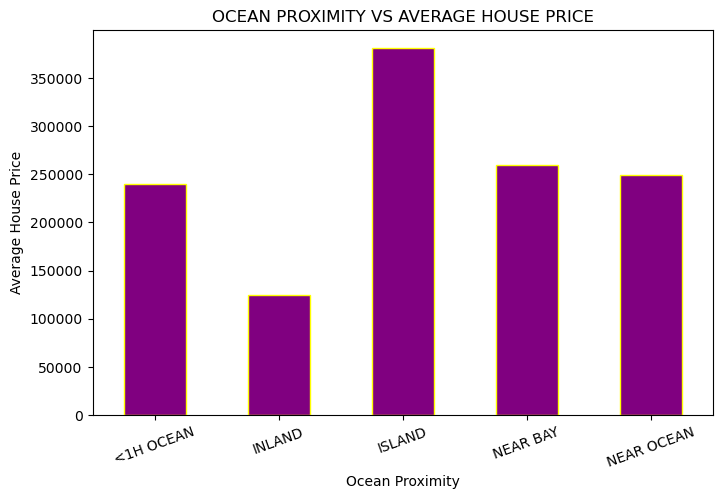

In [22]:
plt.figure(figsize=(8,5))

avg_price.plot(kind='bar', color='PURPLE', edgecolor='YELLOW')

plt.title('OCEAN PROXIMITY VS AVERAGE HOUSE PRICE')
plt.xlabel('Ocean Proximity')
plt.ylabel('Average House Price')

plt.xticks(rotation=20)
plt.show()

1. The highest average house price is observed in the ISLAND category, approximately $380,440.

2. The lowest average house price is observed in the INLAND category, approximately $124,805.

3. Houses in the NEAR BAY category have an average price of approximately $259,212.

4. Houses in the NEAR OCEAN category have an average price of approximately $249,434.

5. Houses in the LESS THAN 1H OCEAN category have an average price of approximately $240,084.

6. Geographical location and ocean proximity show differences in average house prices.

### 5.HOUSE PRICE DISTRIBUTION BY OCEAN PROXIMITY

In [23]:
df.groupby('ocean_proximity')['median_house_value'].describe()

,count,mean,std,min,25%,50%,75%,max
ocean_proximity,,,,,,,,
<1H OCEAN,9136.0,240084.285464,106124.292213,17500.0,164100.0,214850.0,289100.0,500001.0
INLAND,6551.0,124805.392001,70007.908494,14999.0,77500.0,108500.0,148950.0,500001.0
ISLAND,5.0,380440.000000,80559.561816,287500.0,300000.0,414700.0,450000.0,450000.0
NEAR BAY,2290.0,259212.311790,122818.537064,22500.0,162500.0,233800.0,345700.0,500001.0
NEAR OCEAN,2658.0,249433.977427,122477.145927,22500.0,150000.0,229450.0,322750.0,500001.0


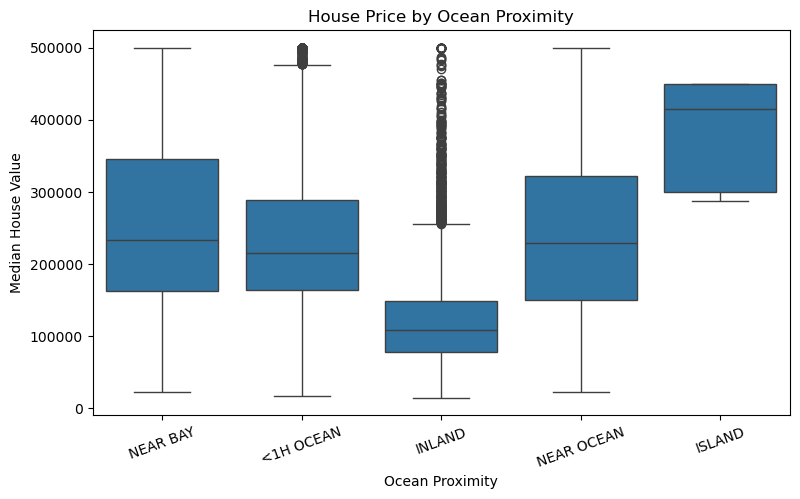

In [24]:
plt.figure(figsize=(9,5))

sns.boxplot(data=df,
            x='ocean_proximity',
            y='median_house_value')

plt.title('House Price by Ocean Proximity')
plt.xlabel('Ocean Proximity')
plt.ylabel('Median House Value')

plt.xticks(rotation=20)
plt.show()

1. Island locations have the highest median house price (approximately $414,700), but the dataset contains only 5 records.

2. Near Bay locations have a median house price of approximately $233,800.

3. Near Ocean locations have a median house price of approximately $229,450.

4. Less than 1H Ocean locations have a median house price of approximately $214,850.

5. Inland locations have the lowest median house price (approximately $108,500).

6. Inland locations contain many high-price outliers, showing that some inland houses are considerably more expensive than others.

### 6. RELATIONSHIP B/W NUMERICAL VARIABLES

In [25]:
corr =df.corr(numeric_only=True)

In [26]:
corr

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069120,0.099773,0.055310,-0.015176,-0.045967
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066484,-0.108785,-0.071035,-0.079809,-0.144160
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.319026,-0.296244,-0.302916,-0.119034,0.105623
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.927058,0.857126,0.918484,0.198050,0.134153
total_bedrooms,0.069120,-0.066484,-0.319026,0.927058,1.000000,0.873535,0.974366,-0.007617,0.049457
population,0.099773,-0.108785,-0.296244,0.857126,0.873535,1.000000,0.907222,0.004834,-0.024650
households,0.055310,-0.071035,-0.302916,0.918484,0.974366,0.907222,1.000000,0.013033,0.065843
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007617,0.004834,0.013033,1.000000,0.688075
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049457,-0.024650,0.065843,0.688075,1.000000


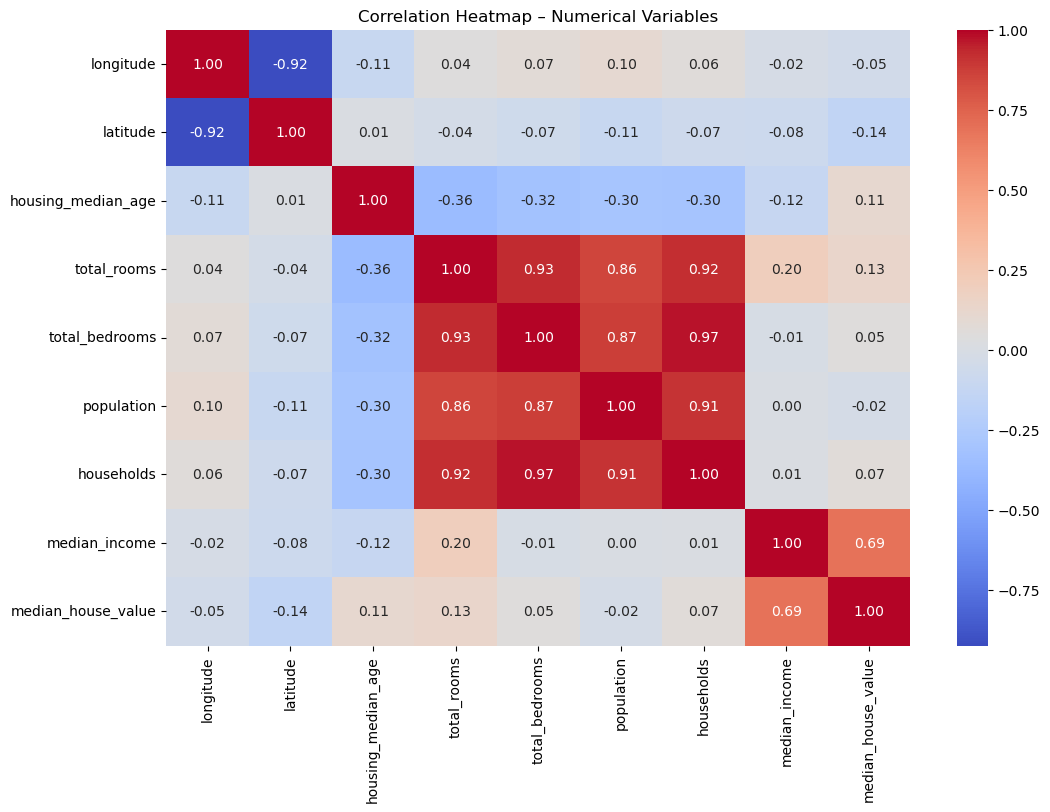

In [27]:

plt.figure(figsize=(12,8))

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap – Numerical Variables')
plt.show()

1. Median Income and Median House Value (0.688): There is a strong positive correlation. As income increases, house prices generally tend to increase.
2. Total Rooms and Total Bedrooms (0.927): They have a very strong positive correlation.
3. Population and Households (0.907): They show a strong positive correlation.
4. Total Rooms and Households (0.918): They also have a strong positive relationship.
5. Latitude and Longitude (-0.925): They show a strong negative correlation.
6. Population and Median House Value (-0.025): There is almost no linear correlation between them.

Overall Conclusion
- The heatmap shows that Median Income has the strongest positive relationship with Median House Value (0.688). This indicates that income is an important factor associated with house prices. Other numerical features also show different levels of correlation.

### 7. HOUSE PRICES BASED ON LOCATION

In [28]:
df.groupby(['latitude', 'longitude'])['median_house_value'].mean().reset_index()

,latitude,longitude,median_house_value
0,32.54,-117.04,67500.0
1,32.55,-117.09,144400.0
2,32.55,-117.06,108800.0
3,32.55,-117.04,93200.0
4,32.56,-117.12,257700.0
...,...,...,...
12585,41.86,-121.93,44000.0
12586,41.88,-123.83,116700.0
12587,41.92,-124.16,75000.0
12588,41.95,-124.14,122400.0


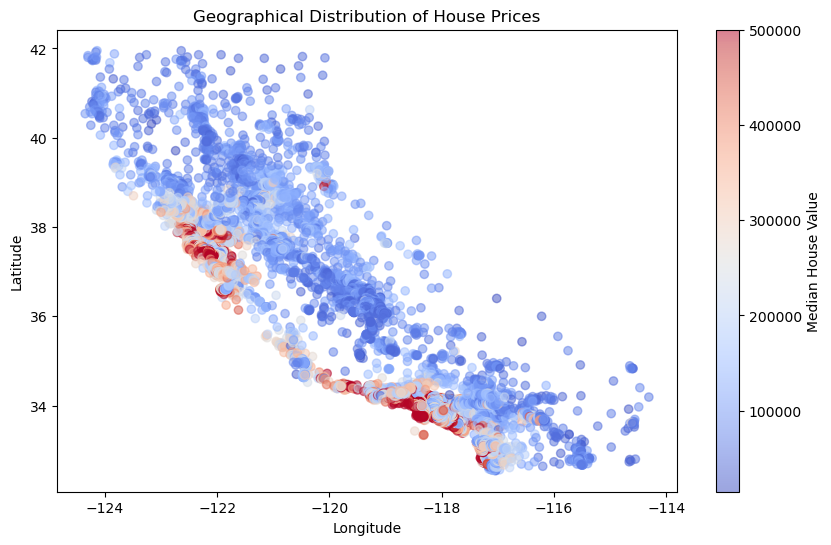

In [29]:
plt.figure(figsize=(10,6))

plt.scatter(
    df['longitude'],
    df['latitude'],
    c=df['median_house_value'],
    cmap='coolwarm',
    alpha=0.5
)

plt.colorbar(label='Median House Value')

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Geographical Distribution of House Prices')

plt.show()

1. The scatter plot shows the relationship between geographical location and median house value in California.

2. Each dot represents a particular geographical location.

3. The X-axis represents longitude and the Y-axis represents latitude.

4. The colour of the dots represents the median house value.

5. Red and orange dots indicate higher house values.

6. Blue dots indicate comparatively lower house values.

7. House values vary from one location to another.

8. Coastal areas generally show higher house values than inland areas.

Conclusion: 
- The scatter plot shows that house prices in California vary according to geographical location.

## DATA PREPROCESSING 

Data Preprocessing is an important step in Machine Learning.
It involves preparing and transforming raw data into a suitable format for building accurate machine learning models.
In this project, feature selection, categorical encoding and feature scaling are performed to prepare the housing dataset for house price prediction.

#### 1. FEATURE SELECTION

Feature Selection is the process of selecting relevant input variables (features) and the target variable for building a Machine Learning model. 
In this project, all input features are selected to predict the median house value.

The input variables are represented as X, and the target variable is represented as y.

In [30]:
X= df.drop("median_house_value",axis=1)
Y= df["median_house_value"]

In [31]:
X.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,NEAR BAY


In [32]:
Y.head()

0    452600.0
1    358500.0
2    352100.0
3    341300.0
4    342200.0
Name: median_house_value, dtype: float64

#### 2. CATEGORICAL ENCODING

Categorical Encoding is the process of converting categorical data into numerical values so that Machine Learning algorithms can understand and process the data.
In this project, the ocean_proximity column is converted into numerical columns using One-Hot Encoding.

In [33]:
X= pd.get_dummies(X,columns= ["ocean_proximity"],dtype=int)

In [34]:
X

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,0,1,0,0,0
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,0,1,0,0,0
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,0,1,0,0,0
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,0,1,0,0,0


In [35]:
X.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,0,0,0,1,0


- The ocean_proximity column was successfully converted into numerical columns using One-Hot Encoding. 
- Five separate binary columns were created for the different ocean proximity categories.
-  This makes the categorical data suitable for Machine Learning algorithms.
-  The value 1 represents the presence of a category.
- The value 0 represents the absence of a category.

#### 3. FEATURE SCALLING

Feature Scaling is the process of bringing numerical features into a similar range. It helps prevent features with larger values from dominating the Machine Learning model. In this project, StandardScaler is used to standardize the numerical features.

In [36]:
from sklearn.preprocessing import StandardScaler

In [37]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [38]:
X_scaled = StandardScaler()


In [39]:
X_scaled

,copy,True
,with_mean,True
,with_std,True


#### 4. CHECKING PREPROCESSED DATA

After completing data preprocessing, the dataset is checked to ensure that all features are properly transformed and ready for Machine Learning model training.

In [40]:
scaler= StandardScaler()

In [41]:
X_scaled = scaler.fit_transform(X)

In [42]:
print(X_scaled.shape)

(20640, 13)


- The preprocessing process was successfully completed.
-  The dataset contains 20,640 rows and 13 features after categorical encoding and feature scaling.
-  The data is now ready for training and testing the Machine Learning model.

## TRAIN-TEST-SPLIT

In [43]:
from sklearn.model_selection import train_test_split

Train-Test Split is the process of dividing the dataset into two parts: training data and testing data. The training data is used to train the Machine Learning model, while the testing data is used to evaluate its performance. In this project, the dataset is divided into 80% training data and 20% testing data.

In [44]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X_scaled, Y, test_size=0.2, random_state=42
)

In [45]:
X_train.shape

(16512, 13)

In [46]:
X_test.shape

(4128, 13)

In [47]:
Y_train.shape

(16512,)

In [48]:
Y_test.shape

(4128,)

- The dataset was successfully divided into 80% training data and 20% testing data.
-  A total of 16,512 records were used for training and 4,128 records were used for testing.
-  The dataset is now ready for Machine Learning model development.

## MACHINE LEARNING MODEL

In [49]:
from sklearn.linear_model import LinearRegression

Machine Learning is a method of teaching computers to learn from data and make predictions. In this project, Linear Regression is used to predict house prices based on different housing features. The model is trained using the training dataset.

In [50]:
model = LinearRegression()

In [51]:
model

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [52]:
model.fit(X_train, Y_train)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


- The Linear Regression model was successfully created and trained using the training dataset.
-  The model learned the relationship between the input features and house prices. It is now ready to predict house prices.

## HOUSE PRICE PREDICTION

House Price Prediction is the process of estimating house prices using a trained Machine Learning model. In this project, the Linear Regression model is used to predict house prices based on the testing dataset.

### 1. PREDICT HOUSE PRICES

In [53]:
y_pred = model.predict(X_test)

In [54]:
y_pred

array([ 54055.44889898, 124225.33893718, 255489.37949166, ...,
       439180.98341181, 120797.55240621, 183386.04993584], shape=(4128,))

#### 2. COMPARE ACTUAL AND PREDICTED PRICES

In [55]:
comparison = pd.DataFrame({
    'Actual Price': Y_test.values,
    'Predicted Price': y_pred
})

comparison.head(10)

,Actual Price,Predicted Price
0,47700.0,54055.448899
1,45800.0,124225.338937
2,500001.0,255489.379492
3,218600.0,268002.431569
4,278000.0,262769.434816
5,158700.0,139606.303956
6,198200.0,290665.423914
7,157500.0,228264.876375
8,340000.0,256506.785610
9,446600.0,407923.858435


- The Linear Regression model successfully generated predicted house prices using the testing dataset.
-  The actual and predicted house prices can be compared to understand the model's prediction performance


## MODEL EVALUATION

Model Evaluation is the process of measuring the performance and accuracy of a Machine Learning model. In this project, different evaluation metrics are used to compare the actual house prices with the predicted house prices.

In [56]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [57]:
#MAE= AVERAGE PREDICTION ERROR
mae = mean_absolute_error(Y_test, y_pred)

#MSE= AVERAGE SQUARD PREDICTION ERROE
mse = mean_squared_error(Y_test, y_pred)

#RMSE= SQUARE ROOT OF MSE
rmse = np.sqrt(mse)

#R2 SCORE= MODEL EXPLAINS HOUSE PRICE VARIATION
r2 = r2_score(Y_test, y_pred)

In [58]:
mae

50670.73824097191

In [59]:
mse

4908476721.156616

In [60]:
rmse

np.float64(70060.52184473518)

In [61]:
r2

0.6254240620553606

1. The Mean Absolute Error (MAE) is 50,760.74, indicating the average prediction error of the model.

2. The Mean Squared Error (MSE) is 4,908,476,721.16.

3. The Root Mean Squared Error (RMSE) is 70,060.52, showing the prediction error in the original house price unit.

4. The R² Score is 0.6254, indicating that the model explains approximately 62.54% of the variation in house prices.



The Linear Regression model achieved an R² score of 62.54%. This indicates that the model provides a reasonable level of prediction performance, but there is still room for improvement.

## ACTUAL VS PREDICTED GRAPH 

Actual vs Predicted Graph is used to compare the actual house prices with the prices predicted by the Machine Learning model. It helps to understand how accurately the model predicts house prices.

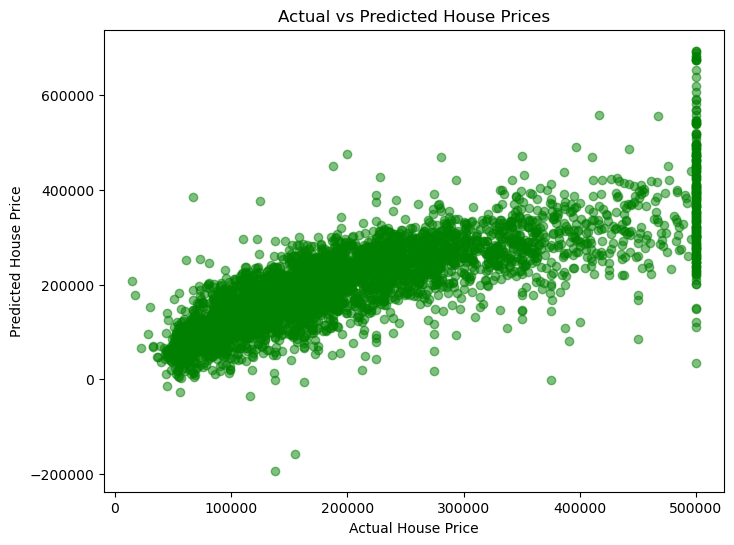

In [62]:
plt.figure(figsize=(8,6))

plt.scatter(Y_test, y_pred ,color="green",alpha=0.5)

plt.xlabel('Actual House Price')
plt.ylabel('Predicted House Price')
plt.title('Actual vs Predicted House Prices')

plt.show()

1. The scatter plot shows a positive relationship between the input values and predicted house prices.
2. As the input value increases, the predicted house price generally increases.
3. Most data points are concentrated between 50,000 and 300,000.
4. The model predicts house prices mainly within the range of 50,000 to 350,000.
5. Some outliers are present, with unusually high and low predicted prices.
6. The data points are widely scattered, indicating that the model does not predict every house price accurately.
7. overall the graph shows that the model captures a positive trend in house prices, but there is still some prediction error.

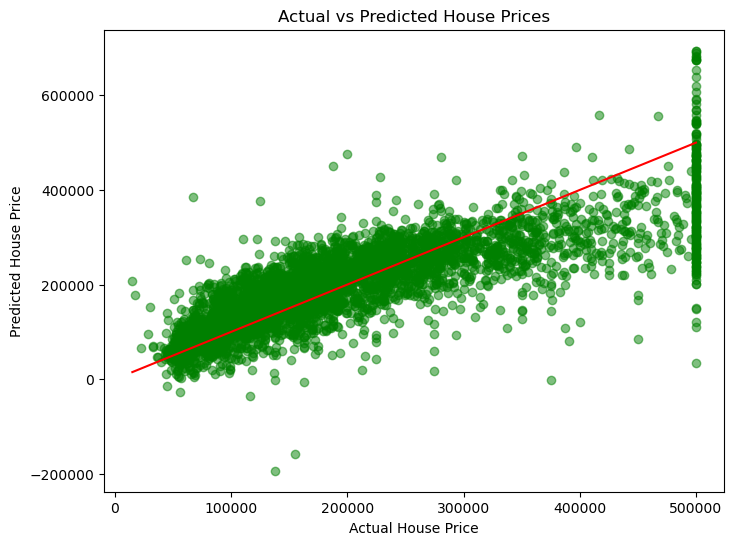

In [63]:
plt.figure(figsize=(8,6))

plt.scatter(Y_test, y_pred,color="green", alpha=0.5)

plt.plot(
    [Y_test.min(), Y_test.max()],
    [Y_test.min(), Y_test.max()],
    color='red'
)

plt.xlabel('Actual House Price')
plt.ylabel('Predicted House Price')
plt.title('Actual vs Predicted House Prices')

plt.show()

1. The graph shows a positive linear relationship between house prices and predicted house prices.
2. The regression line indicates an increasing trend in house prices.
3. Most data points are concentrated around the regression line.
4. Some data points are scattered away from the regression line, indicating prediction errors.
5. A few outliers are present in the dataset.
6. The model captures the general trend but does not predict all house prices accurately.

## KEY FINDINGS

1. The dataset contains a total of 20,640 housing records with 10 original features.

2. Median Income has a strong positive correlation (0.688) with Median House Value.

3. House prices vary depending on their proximity to the ocean.

4. Inland areas generally have lower median house prices compared to coastal areas.

5. The Island category has the highest median house price. However, it contains very few records.

6. Total Rooms and Total Bedrooms have a very strong positive correlation (0.927).

7. Population and Households show a strong positive correlation (0.907).

8. Population and Median House Value have a very weak negative correlation (-0.025).

9. Areas with higher median income generally have higher house prices.

10. House prices vary across different geographical locations in California.

11. Some areas contain unusually high house prices, which are identified as outliers.

12. Ocean Proximity is an important factor associated with house prices.

13. The Geographical Scatter Plot helps identify variations in house prices across different locations.

14. Data preprocessing successfully converted categorical data into numerical format and standardized the features.

15. The Linear Regression model was successfully trained and used to predict house prices.

16. The Mean Absolute Error (MAE) of the model is 50,760.74.

17. The Root Mean Squared Error (RMSE) of the model is 70,060.52.

18. The Linear Regression model achieved an R² Score of 0.6254, indicating that it explains approximately 62.54% of the variation in house prices.

## LIMITATIONS


1. The dataset contains limited information about housing features.

2. The Linear Regression model may not capture complex relationships between variables.

3. House prices are influenced by several factors that are not included in the dataset.

4. The model achieved an R² score of 62.54%, indicating that some price variations remain unexplained.

5. The dataset contains outliers that may affect prediction accuracy. 

## CONCLUSION



This project focused on analyzing and predicting house prices using the California Housing Dataset. Exploratory Data Analysis and data visualization helped identify important patterns and relationships in housing prices.

A Linear Regression model was developed to predict house prices using different housing features. The model achieved an R² score of 0.6254, explaining approximately 62.54% of the variation in house prices.

Overall, this project provided a better understanding of data analysis, data preprocessing, visualization and Machine Learning techniques. It also demonstrated how Machine Learning can be used for house price prediction.
Malayalam